# NEXUS — Training Data Preparation & Chronological Split

**Input:** `data/processed/m5_features.parquet`  
**Outputs:** `train.parquet`, `validation.parquet`, `test.parquet`, and `split_metadata.json`.

This notebook prepares the engineered data for model training. It does not train models yet.


## 1. Imports and paths

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns",
50)
pd.set_option("display.width",
140)

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name in {
    "src",
    "notebooks"
} else cwd
DATA_DIR = PROJECT_ROOT / "data" / "processed"
INPUT_PATH = DATA_DIR / "m5_features.parquet"

print("Project root:", PROJECT_ROOT)
print("Input exists:", INPUT_PATH.exists())
print("Input path:", INPUT_PATH)


Project root: c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting
Input exists: True
Input path: c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting\data\processed\m5_features.parquet


## 2. Load the engineered dataset

In [2]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
if not INPUT_PATH.exists():
    raise FileNotFoundError(f"Could not find {INPUT_PATH}. Run the feature-engineering notebook first.")

features = pd.read_parquet(INPUT_PATH)
features[
    "date"
] = pd.to_datetime(features[
    "date"
])

print("Shape:", features.shape)
print("Products:", features[
    "item_id"
].nunique())
print("Stores:", features[
    "store_id"
].nunique())
print("Product-store series:", features.groupby([
    "item_id",
    "store_id"
]).ngroups)
print("Date range:", features[
    "date"
].min(),
"to", features[
    "date"
].max())
display(features.head())


Shape: (382600, 14)
Products: 20
Stores: 10
Product-store series: 200
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


,item_id,store_id,date,sales,day_of_week,is_weekend,month,sell_price,price_missing,snap,lag_1,lag_7,rolling_mean_7,rolling_mean_28
0,HOBBIES_1_001,CA_1,2011-01-29,0,5,1,1,NaN,1,0,NaN,NaN,NaN,NaN
1,HOBBIES_1_001,CA_1,2011-01-30,0,6,1,1,NaN,1,0,0.0,NaN,NaN,NaN
2,HOBBIES_1_001,CA_1,2011-01-31,0,0,0,1,NaN,1,0,0.0,NaN,NaN,NaN
3,HOBBIES_1_001,CA_1,2011-02-01,0,1,0,2,NaN,1,1,0.0,NaN,NaN,NaN
4,HOBBIES_1_001,CA_1,2011-02-02,0,2,0,2,NaN,1,1,0.0,NaN,NaN,NaN


## 3. Recheck missing pricing pattern

In [4]:
price_analysis = features.groupby("price_missing")["sales"].agg(["count", "mean", "sum", "min", "max"])
display(price_analysis)

print(f"Missing price percentage: {features['price_missing'].mean() * 100:.2f}%")
missing_price_positive_sales = (features[
    "price_missing"
].eq(1) & features[
    "sales"
].gt(0)).sum()
print("Rows with missing price and positive sales:", missing_price_positive_sales)

assert missing_price_positive_sales == 0, "Missing-price pattern differs from the earlier inspection; investigate."


,count,mean,sum,min,max
price_missing,,,,,
0,324283,1.429998,463724,0,93
1,58317,0.000000,0,0,0


Missing price percentage: 15.24%
Rows with missing price and positive sales: 0


## 4. Define target and input features

`sales` is the target, not an input feature. `item_id` and `store_id` are identifiers that will be encoded in the model-training pipeline.


In [10]:
TARGET = "sales"
IDENTIFIER_COLUMNS = [
    "item_id",
    "store_id",
    "date"
]

NUMERIC_FEATURES = [
    "day_of_week",
    "is_weekend",
    "month",
    "sell_price",
    "price_missing",
    "snap",
    "lag_1",
    "lag_7",
    "rolling_mean_7",
    "rolling_mean_28"
]
CATEGORICAL_FEATURES = [
    "item_id",
    "store_id"
]
FEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERIC_FEATURES

required = set(IDENTIFIER_COLUMNS + [TARGET
] + FEATURE_COLUMNS)
missing_columns = required.difference(features.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

print("Target:", TARGET)
print("Input features:", FEATURE_COLUMNS)


Target: sales
Input features: ['item_id', 'store_id', 'day_of_week', 'is_weekend', 'month', 'sell_price', 'price_missing', 'snap', 'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_mean_28']


In [11]:
# --- 5-DAY HORIZON FEATURE & TARGET ENGINEERING ---
HORIZON = 5

# Ensure strict sorting by series and time
features = features.sort_values(["item_id", "store_id", "date"]).reset_index(drop=True)

# 1. Direct Target: Cumulative sales from t+1 to t+5
features["target_5d"] = (
    features.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.iloc[::-1].rolling(HORIZON, min_periods=HORIZON).sum().iloc[::-1].shift(-1))
)

# 2. Leak-free backward features available at decision day t0
features["lag_0"] = features["sales"]
features["lag_7"] = features.groupby(["item_id", "store_id"])["sales"].shift(7)
features["lag_14"] = features.groupby(["item_id", "store_id"])["sales"].shift(14)

features["hist_sum_5d"] = (
    features.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.rolling(HORIZON, min_periods=HORIZON).sum())
)
features["hist_mean_7d"] = (
    features.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.rolling(7, min_periods=7).mean())
)
features["hist_mean_28d"] = (
    features.groupby(["item_id", "store_id"])["sales"]
    .transform(lambda s: s.rolling(28, min_periods=14).mean())
)

# 3. Seasonal Naive 5-day baseline
features["seasonal_naive_5d"] = features.groupby(["item_id", "store_id"])["hist_sum_5d"].shift(7)

# Update Target and Feature list definitions
TARGET = "target_5d"
NUMERIC_FEATURES = [
    "day_of_week",
    "is_weekend",
    "month",
    "sell_price",
    "price_missing",
    "snap",
    "lag_0",
    "lag_7",
    "lag_14",
    "hist_sum_5d",
    "hist_mean_7d",
    "hist_mean_28d",
]
FEATURE_COLUMNS = CATEGORICAL_FEATURES + NUMERIC_FEATURES

## 5. Handle insufficient historical data

The first rows of each product-store series do not have enough previous observations to calculate lag and rolling features. For this first model experiment, remove rows without a 28-day rolling average. We retain missing prices; they are not the same as missing sales or missing history.


In [12]:
# Drop rows missing the 28-day rolling window or the forward 5-day target
clean_cols = ["target_5d", "seasonal_naive_5d", "hist_mean_28d"]
print("Missing values in required 5-day columns:")
display(features[clean_cols].isna().sum().to_frame("missing_count"))

model_data = features.dropna(subset=clean_cols).copy()
print("Rows remaining for 5-day split:", len(model_data))

Missing values in required 5-day columns:


,missing_count
target_5d,1000
seasonal_naive_5d,2200
hist_mean_28d,2600


Rows remaining for 5-day split: 379000


## 6. Inspect remaining missing values

In [13]:
missing_summary = pd.DataFrame({"missing_count": model_data[FEATURE_COLUMNS
].isna().sum(),
"missing_percentage": (model_data[FEATURE_COLUMNS
].isna().mean() * 100).round(2)
})
display(missing_summary)

print("Rows with missing price retained:", model_data[
"price_missing"
].eq(1).sum())


,missing_count,missing_percentage
item_id,0,0.00
store_id,0,0.00
day_of_week,0,0.00
is_weekend,0,0.00
month,0,0.00
sell_price,56639,14.94
price_missing,0,0.00
snap,0,0.00
lag_0,0,0.00
lag_7,0,0.00


Rows with missing price retained: 56639


## 7. Create chronological train / validation / test splits

Split by unique dates, not random rows, so all product-store observations for a date remain in the same partition. We use approximately 80% of dates for training,
10% for validation, and 10% for testing.


In [14]:
unique_dates = np.array(sorted(model_data["date"].unique()))
n_dates = len(unique_dates)

train_end_idx = int(n_dates * 0.80)
validation_end_idx = int(n_dates * 0.90)

train_end_date = pd.Timestamp(unique_dates[train_end_idx - 1
])
validation_end_date = pd.Timestamp(unique_dates[validation_end_idx - 1
])

train = model_data.loc[model_data[
"date"
] <= train_end_date
].copy()
validation = model_data.loc[
    (model_data[
"date"
] > train_end_date) &
    (model_data[
"date"
] <= validation_end_date)
].copy()
test = model_data.loc[model_data[
"date"
] > validation_end_date
].copy()

split_summary = pd.DataFrame([
{
"split": "train",
"rows":len(train),
"start_date":train[
    "date"
].min(),
"end_date":train[
    "date"
].max(),
"unique_dates":train[
    "date"
].nunique()
},
{
"split": "validation",
"rows":len(validation),
"start_date":validation[
    "date"
].min(),
"end_date":validation[
    "date"
].max(),
"unique_dates":validation[
    "date"
].nunique()
},
{
"split": "test",
"rows":len(test),
"start_date":test[
    "date"
].min(),
"end_date":test[
    "date"
].max(),
"unique_dates":test[
    "date"
].nunique()
},
])
display(split_summary)


,split,rows,start_date,end_date,unique_dates
0,train,303200,2011-02-11,2015-04-06,1516
1,validation,37800,2015-04-07,2015-10-12,189
2,test,38000,2015-10-13,2016-04-19,190


## 8. Visualise the date ranges

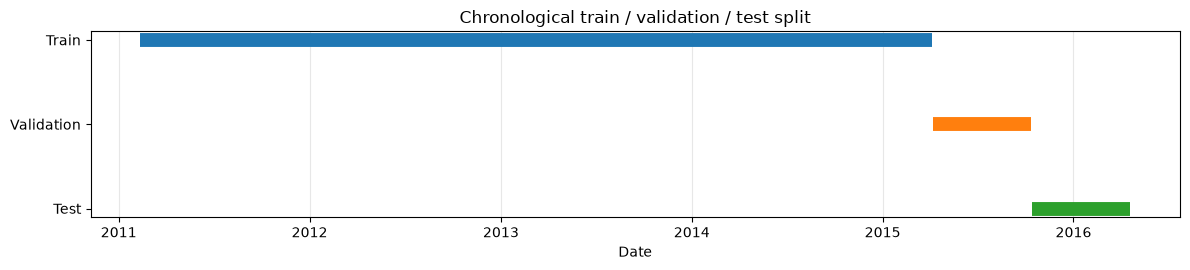

In [15]:
plt.figure(figsize=(12, 2.8))
ranges = [
    ("Train", train[
"date"
].min(), train[
"date"
].max(),
3),
    ("Validation", validation[
"date"
].min(), validation[
"date"
].max(),
2),
    ("Test", test[
"date"
].min(), test[
"date"
].max(),
1),
]
for label, start, end, y in ranges:
    plt.plot([start, end
],
[y, y
], linewidth=10, solid_capstyle="butt", label=label)
plt.yticks([
1,
2,
3
],
[
"Test",
"Validation",
"Train"
])
plt.xlabel("Date")
plt.title("Chronological train / validation / test split")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Validate split integrity

In [16]:
assert len(train) > 0 and len(validation) > 0 and len(test) > 0
assert train[
"date"
].max() < validation[
"date"
].min()
assert validation[
"date"
].max() < test[
"date"
].min()

for name, split in [("train", train), ("validation", validation), ("test", test)
]:
    duplicates = split.duplicated([
"item_id",
"store_id",
"date"
]).sum()
    print(f"{name}: {len(split):,} rows | duplicate keys: {duplicates}")
    assert duplicates == 0

print("Chronological split checks passed.")


train: 303,200 rows | duplicate keys: 0
validation: 37,800 rows | duplicate keys: 0
test: 38,000 rows | duplicate keys: 0
Chronological split checks passed.


## 10. Check product-store coverage

In [17]:
def series_coverage(frame):
    return set(zip(frame[
"item_id"
], frame[
"store_id"
]))

train_series = series_coverage(train)
validation_series = series_coverage(validation)
test_series = series_coverage(test)

print("Train combinations:", len(train_series))
print("Validation combinations:", len(validation_series))
print("Test combinations:", len(test_series))
print("Validation combinations missing vs train:", len(train_series - validation_series))
print("Test combinations missing vs train:", len(train_series - test_series))

assert train_series == validation_series == test_series


Train combinations: 200
Validation combinations: 200
Test combinations: 200
Validation combinations missing vs train: 0
Test combinations missing vs train: 0


## 11. Save split datasets and metadata

In [18]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

train_path = DATA_DIR / "train_5d.parquet"
validation_path = DATA_DIR / "validation_5d.parquet"
test_path = DATA_DIR / "test_5d.parquet"
metadata_path = DATA_DIR / "split_metadata_5d.json"

train.to_parquet(train_path, index=False)
validation.to_parquet(validation_path, index=False)
test.to_parquet(test_path, index=False)

metadata = {
    "input_file": INPUT_PATH.name,
    "target": TARGET,
    "horizon_days": 5,
    "feature_columns": FEATURE_COLUMNS,
    "identifier_columns": IDENTIFIER_COLUMNS,
    "baseline_column": "seasonal_naive_5d",
    "split_method": "Chronological split over unique dates",
    "train_fraction": 0.80,
    "validation_fraction": 0.10,
    "test_fraction": 0.10,
    "train_start": str(train["date"].min().date()),
    "train_end": str(train["date"].max().date()),
    "validation_start": str(validation["date"].min().date()),
    "validation_end": str(validation["date"].max().date()),
    "test_start": str(test["date"].min().date()),
    "test_end": str(test["date"].max().date()),
    "rows": {
        "train": int(len(train)),
        "validation": int(len(validation)),
        "test": int(len(test)),
    },
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved 5-day dataset splits successfully:")
print(train_path)
print(validation_path)
print(test_path)
print(metadata_path)

Saved 5-day dataset splits successfully:
c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting\data\processed\train_5d.parquet
c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting\data\processed\validation_5d.parquet
c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting\data\processed\test_5d.parquet
c:\Akhil\AI_Engineer\2ndProject\nexus-forecasting\data\processed\split_metadata_5d.json


## 12. Summary and next step

The data is now prepared for model training. Missing prices are retained. Do not impute them globally here: imputation, if needed, must be fitted on training data only inside each model's preprocessing pipeline. XGBoost can also be evaluated with native missing-value handling.

Next notebook: establish a naïve baseline, train Linear Regression / Random Forest / XGBoost, compare MAE, RMSE and WAPE on validation data, compare pricing-feature experiments, and evaluate the selected model once on the held-out test set.
